# Exercice 2

- Reproduire le nuage de point du graphe présenté dans « Régression logistique – A quoi cela ressemble ? » sur base des données de la p.156 (voir le fichier disease.txt sur le portail)

- Utiliser la librairie sklearn pour optimiser un modèle logistique

- Comparer avec les valeurs du modèle annoncées en p.159

- Ajouter la courbe optimale au nuage de point

In [55]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
import math

On charge les données

In [39]:
df = pd.read_csv("Disease.txt", index_col='id')

df.head()

,age,disease
id,,
1,25,0
2,29,0
3,30,0
4,31,0
5,32,0


On représente le nuage de points

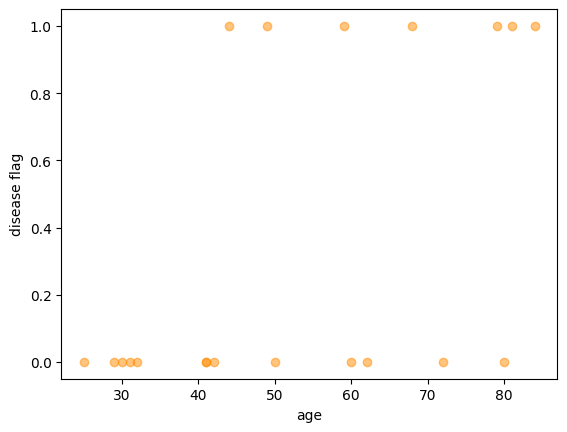

In [40]:
plt.plot(df['age'],df['disease'], 'o', color='darkorange', lw=lw, alpha=0.5)
plt.xlabel('age')
plt.ylabel('disease flag')
plt.show()

In [45]:
# Variable explicative
X = df.drop(['disease'],axis=1)

# Variable cible
y = df['disease']

logreg = LogisticRegression()

logreg.fit(X, y)

# b0, b1
logreg.intercept_, logreg.coef_

(array([-4.36803094]), array([[0.06688661]]))

In [46]:
# Tableau de [P(sain), P(malade)]
# On choisit la 2nd colonne pour expliquer mais c'est le complément de la 1ère
y_pred = logreg.predict_proba(X)[:,1]
y_pred

array([0.06321775, 0.08103854, 0.08616132, 0.09157566, 0.09729401,
       0.16442301, 0.16442301, 0.17381984, 0.19387577, 0.25150772,
       0.26430719, 0.39610497, 0.41221055, 0.44495863, 0.54494295,
       0.61011716, 0.71422862, 0.72768278, 0.74073345, 0.77737671])

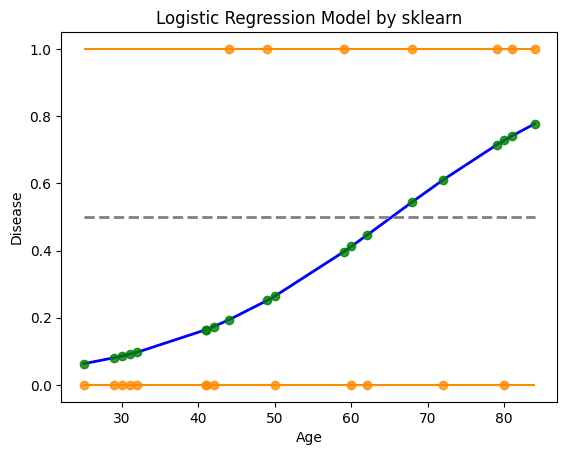

In [ ]:
# Proba sous forme continue
plt.plot(X, y_pred, lw=2, color='blue')

# Probas sous forme de points
plt.plot(X, y_pred, 'o', color='green', alpha=0.8)

# Si malade ou non
plt.plot(X, y, 'o', color='darkorange', lw=2, alpha=0.8)

plt.hlines(0.5,min(X.values),max(X.values), color='grey', lw=2, linestyle='--')
plt.hlines(0.0, min(X.values), max(X.values), color='darkorange', linestyle='-')
plt.hlines(1.0, min(X.values), max(X.values), color='darkorange', linestyle='-')

plt.title('Logistic Regression Model by sklearn')
plt.xlabel('Age')
plt.ylabel('Disease')
plt.show()

C:\Users\Christophe\AppData\Local\Temp\ipykernel_17768\2363887591.py:7: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return math.exp(g(x['age']))/(1+math.exp(g(x['age'])))


NameError: name 'data_df' is not defined

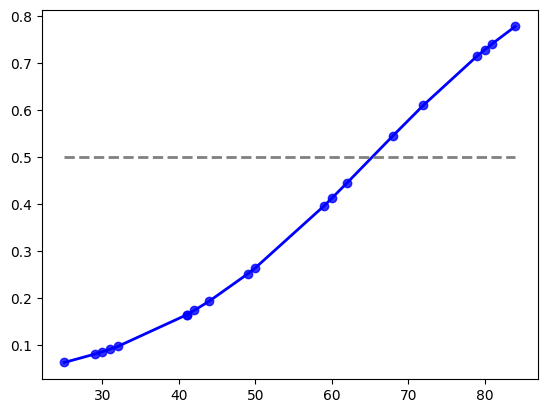

In [ ]:
def g(x):
    b0 = logreg.intercept_
    b1 = logreg.coef_[0][0]
    return b0+b1*x

def pi(x):
    return math.exp(g(x['age']))/(1+math.exp(g(x['age'])))

df['analytic'] = df.apply(pi,axis=1)

plt.plot(X, y_pred, lw=2, color='blue')
plt.plot(X, y_pred, 'o', color='green', alpha=0.8)
plt.plot(X, df['analytic'], color='red')

plt.hlines(0.5,min(X.values),max(X.values), color='grey', lw=2, linestyle='--')
plt.hlines(0.0, min(X.values), max(X.values), color='darkorange', linestyle='-')
plt.hlines(1.0, min(X.values), max(X.values), color='darkorange', linestyle='-')

plt.title('Logistic Regression Model by sklearn')
plt.xlabel('Age')
plt.ylabel('Disease')
plt.show()